# Section 5.1 — Surface vs. behavioural similarity (Qwen2.5-7B-Instruct)

Generates the outputs for the preliminary experiment of Section 5.1 and computes the two 16 × 16 cosine-similarity matrices behind Figs. 2 and 3.

1. The 16 intent-preserving variants of *"Explain recursion"* (Table 3 of the manuscript) are sent to **`Qwen/Qwen2.5-7B-Instruct`** with greedy decoding (`do_sample=False`, `max_new_tokens=512`, seed 42) in **bf16**, no quantisation.
2. Prompts and outputs are embedded with `sentence-transformers/all-MiniLM-L6-v2` (normalised).
3. The two cosine matrices are compared on their 120 strict-upper-triangle pairs (Pearson and Spearman).
4. The outputs are saved to `recursion_real_outputs.csv` and a provenance record to `provenance_manifest.json`.

**Recorded run (stored cell outputs):** cloud NVIDIA A100-PCIE-40GB. Both output files are included in `data/surface_vs_behaviour/`.

The Mantel permutation test reported in the paper (999,999 permutations, seed 42) is computed from the saved outputs by `analysis/surface_vs_behaviour.py` and `figures/notebooks/fig3_similarity_scatter.ipynb`, which re-embed `recursion_real_outputs.csv` at full precision.

**Hardware:** bf16 weights need about 16 GB, so a ≥ 24 GB GPU is required; the run peaked at about 19 GB on the 40 GB A100.

**Release note:** the code cells are exactly as run; only the markdown text and two code comments were edited for publication.

## 1. Environment setup (run once per pod)

In [1]:
# Jarvis Labs pods usually ship with torch + CUDA already. Install the rest.
!pip install -q -U transformers accelerate sentence-transformers seaborn scipy

import torch, transformers, sentence_transformers, numpy as np
print("torch", torch.__version__)
print("transformers", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    name = torch.cuda.get_device_name(0)
    cc = torch.cuda.get_device_capability(0)
    total = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"GPU: {name} | compute capability {cc} | {total:.0f} GB VRAM")
    print("native bf16:", cc[0] >= 8)



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
torch 2.11.0+cu130
transformers 5.12.1
CUDA available: True
GPU: NVIDIA A100-PCIE-40GB | compute capability (8, 0) | 42 GB VRAM
native bf16: True


## 2. Authenticate with Hugging Face (optional)

`Qwen/Qwen2.5-7B-Instruct` is not gated, so a token is optional. If you have one, export it before launching Jupyter so that no secret is written into the notebook:

```bash
export HF_TOKEN=<your token>
```

The cell below picks up the environment variable and otherwise falls back to an interactive prompt.

In [2]:
import os
from huggingface_hub import login

tok = os.environ.get("HF_TOKEN")
if tok:
    login(tok)
    print("Logged in via HF_TOKEN environment variable.")
else:
    login()  # interactive fallback — paste token when prompted


## 3. The 16 prompts

The prompts listed in Table 3 of the manuscript, in order P1…P16, varying instruction strength/focus (P1–P4), audience/expertise (P5–P8), reasoning style (P9–P12) and output format/constraints (P13–P16). The cell after it checks that there are 16 distinct, non-empty prompts.

In [3]:
# === The 16 prompts of the preliminary experiment (Table 3 of the manuscript) ===
# Order matters: index 0 = P1, ..., index 15 = P16.
prompts = [
    "Explain recursion.",   # P1  (instruction strength/focus)
    "Explain recursion in 3–4 sentences, focusing only on the core idea.",   # P2
    "Explain recursion with a simple example in any programming language.",   # P3
    "Explain recursion and list three common mistakes beginners make.",   # P4
    "Explain recursion to a 10-year-old using a story from daily life.",   # P5  (audience / expertise)
    "Explain recursion to a first-year CS student who understands loops but is new to functions.",   # P6
    "Explain recursion to a CS graduate preparing for coding interviews, including time and space complexity.",   # P7
    "Explain recursion to an algorithms researcher; assume they know mathematical induction.",   # P8
    "First list the key ideas needed to understand recursion. Then explain each idea in 2–3 sentences, and finally give a short summary.",   # P9  (reasoning style)
    "Explain recursion step by step, starting from an everyday analogy and gradually moving to code.",  # P10
    "Explain recursion by first giving a definition, then an example, and finally explaining why the base case is essential.",  # P11
    "Explain recursion by comparing it with iteration and highlighting situations where recursion is preferable.",  # P12
    "Explain recursion using bullet points only.",  # P13 (output format / constraints)
    "Explain recursion without using any code or mathematical notation; use only analogies.",  # P14
    "Explain recursion using a Python example with clear comments on each important line.",  # P15
    "Explain recursion in a confusing way, then rewrite your explanation to make it as clear as possible.",  # P16
]

prompt_ids = [f"P{i}" for i in range(1, 17)]
categories = {
    **{f"P{i}": "instruction" for i in range(1, 5)},
    **{f"P{i}": "audience"    for i in range(5, 9)},
    **{f"P{i}": "reasoning"   for i in range(9, 13)},
    **{f"P{i}": "format"      for i in range(13, 17)},
}


In [4]:
# === INTEGRITY GUARD — do not remove ===
assert len(prompts) == 16, f"Expected 16 prompts, got {len(prompts)}"
for i, p in enumerate(prompts, 1):
    assert p and not p.strip().startswith("<<<"), (
        f"Prompt P{i} is still a placeholder. Paste the real Table 5 text before running."
    )
    assert len(p.strip()) > 0, f"Prompt P{i} is empty."
assert len(set(prompts)) == 16, "Two prompts are identical — check for copy/paste errors."
print("Guard passed: 16 distinct, real prompts loaded.")


Guard passed: 16 distinct, real prompts loaded.


## 4. Load Qwen-2.5-7B-Instruct (bf16 on A100, full precision)

In [5]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"

# A100 is compute capability 8.0 -> bf16 (matches the main pipeline). No quantization.
cc = torch.cuda.get_device_capability(0)
DTYPE = torch.bfloat16 if cc[0] >= 8 else torch.float16
print(f"Using dtype: {DTYPE}")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=DTYPE, device_map="auto",
)
model.eval()

alloc = torch.cuda.memory_allocated() / 1e9
print(f"Model loaded. VRAM allocated after load: {alloc:.1f} GB")


Using dtype: torch.bfloat16


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Model loaded. VRAM allocated after load: 15.2 GB


## 5. Generate the 16 outputs — greedy, deterministic

`do_sample=False` is greedy decoding (deterministic for a given machine and dtype); seeds are set as well. Each prompt is wrapped in the model's chat template.

In [6]:
import random, numpy as np, pandas as pd, torch

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

MAX_NEW_TOKENS = 512

def generate(prompt_text):
    messages = [{"role": "user", "content": prompt_text}]
    inputs = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True,
        return_tensors="pt", return_dict=True   # <- return BatchEncoding
    ).to(model.device)
    input_len = inputs["input_ids"].shape[-1]    # <- length from input_ids
    with torch.no_grad():
        out = model.generate(
            **inputs,                            # <- unpack ids + attention_mask
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,                     # greedy
            pad_token_id=tokenizer.eos_token_id,
        )
    gen = out[0][input_len:]                     # strip the prompt tokens
    return tokenizer.decode(gen, skip_special_tokens=True).strip()

outputs = []
for pid, p in zip(prompt_ids, prompts):
    txt = generate(p)
    outputs.append(txt)
    print(f"{pid}: {len(txt)} chars  | {txt[:80]!r}")

df = pd.DataFrame({
    "prompt_id": prompt_ids,
    "category": [categories[p] for p in prompt_ids],
    "prompt_text": prompts,
    "output_text": outputs,
})
df.to_csv("recursion_real_outputs.csv", index=False)
print("\nSaved recursion_real_outputs.csv")
df.head()


P1: 2158 chars  | 'Recursion is a fundamental concept in computer science and mathematics where a f'
P2: 280 chars  | 'Recursion is a programming technique where a function calls itself to solve a pr'
P3: 1603 chars  | 'Certainly! Recursion is a programming technique where a function calls itself on'
P4: 2296 chars  | 'Recursion is a programming technique where a function calls itself one or more t'
P5: 1867 chars  | "Sure! Let's imagine you have a big box of colorful building blocks. Each block i"
P6: 2307 chars  | 'Sure! Recursion is a powerful concept in computer science that can be a bit tric'
P7: 2365 chars  | 'Certainly! Recursion is a fundamental concept in computer science that involves '
P8: 2306 chars  | 'Certainly! Recursion is a fundamental concept in computer science and algorithm '
P9: 2426 chars  | '### Key Ideas Needed to Understand Recursion\n\n1. **Base Case**: The condition un'
P10: 2193 chars  | "Sure! Let's start with an everyday analogy to understand recursion, an

,prompt_id,category,prompt_text,output_text
0,P1,instruction,Explain recursion.,Recursion is a fundamental concept in computer...
1,P2,instruction,"Explain recursion in 3–4 sentences, focusing o...",Recursion is a programming technique where a f...
2,P3,instruction,Explain recursion with a simple example in any...,Certainly! Recursion is a programming techniqu...
3,P4,instruction,Explain recursion and list three common mistak...,Recursion is a programming technique where a f...
4,P5,audience,Explain recursion to a 10-year-old using a sto...,Sure! Let's imagine you have a big box of colo...


## 6. Embed prompts and outputs (same embedder as the paper)

In [7]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

prompt_emb = embedder.encode(prompts, convert_to_numpy=True, normalize_embeddings=True)
output_emb = embedder.encode(outputs, convert_to_numpy=True, normalize_embeddings=True)

prompt_sim = cosine_similarity(prompt_emb)   # 16x16, REAL prompts
output_sim = cosine_similarity(output_emb)   # 16x16, REAL outputs
print("prompt_sim:", prompt_sim.shape, " output_sim:", output_sim.shape)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

prompt_sim: (16, 16)  output_sim: (16, 16)


## 7. Does prompt similarity predict output similarity?

Compared on the strict upper triangle (120 unique pairs; the diagonal is trivially 1 and would inflate the correlation).

In [8]:
from scipy.stats import pearsonr, spearmanr

iu = np.triu_indices(16, k=1)
p_vals = prompt_sim[iu]
o_vals = output_sim[iu]

r_p, p_p = pearsonr(p_vals, o_vals)
r_s, p_s = spearmanr(p_vals, o_vals)

print(f"n pairs            : {len(p_vals)}")
print(f"Prompt sim  mean   : {p_vals.mean():.3f}  (min {p_vals.min():.3f}, max {p_vals.max():.3f})")
print(f"Output sim  mean   : {o_vals.mean():.3f}  (min {o_vals.min():.3f}, max {o_vals.max():.3f})")
print(f"Pearson  r = {r_p:.3f}, p = {p_p:.4f}")
print(f"Spearman r = {r_s:.3f}, p = {p_s:.4f}")


n pairs            : 120
Prompt sim  mean   : 0.694  (min 0.436, max 0.896)
Output sim  mean   : 0.671  (min 0.217, max 0.932)
Pearson  r = 0.484, p = 0.0000
Spearman r = 0.144, p = 0.1165


## 8. Figures — the two heatmaps for the paper

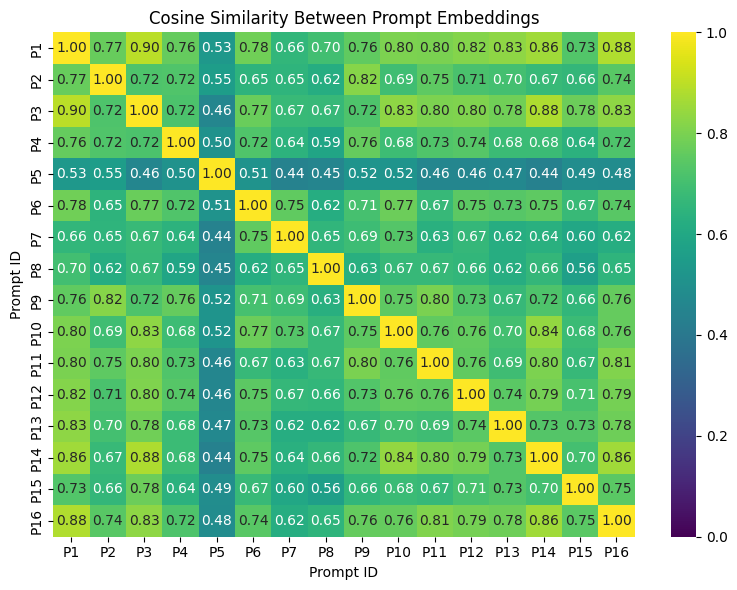

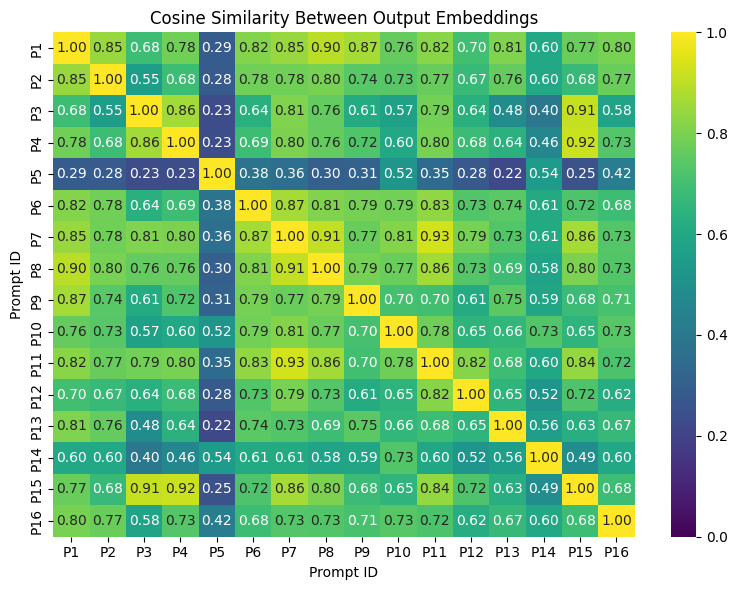

In [9]:
import matplotlib.pyplot as plt, seaborn as sns

def heatmap(mat, title, fname):
    plt.figure(figsize=(8, 6))
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="viridis",
                xticklabels=prompt_ids, yticklabels=prompt_ids, vmin=0, vmax=1)
    plt.title(title); plt.xlabel("Prompt ID"); plt.ylabel("Prompt ID")
    plt.tight_layout()
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

heatmap(prompt_sim, "Cosine Similarity Between Prompt Embeddings",
        "fig_prompt_similarity.png")
heatmap(output_sim, "Cosine Similarity Between Output Embeddings",
        "fig_output_similarity.png")


## 9. (Optional) Pairwise scatter — the visual of the correlation

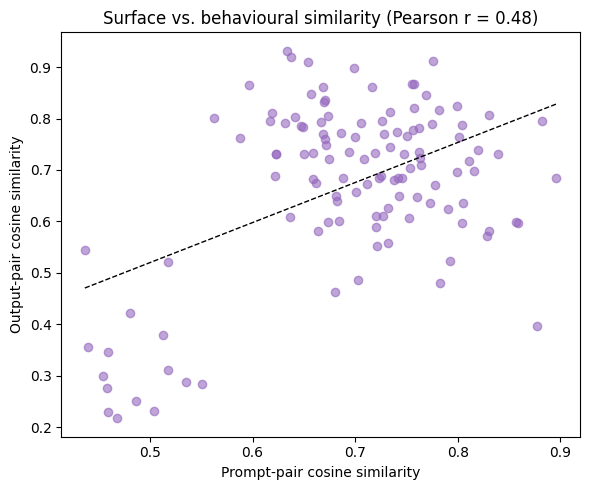

In [10]:
plt.figure(figsize=(6, 5))
plt.scatter(p_vals, o_vals, alpha=0.6, color="tab:purple")
plt.xlabel("Prompt-pair cosine similarity")
plt.ylabel("Output-pair cosine similarity")
plt.title(f"Surface vs. behavioural similarity (Pearson r = {r_p:.2f})")
m, b = np.polyfit(p_vals, o_vals, 1)
xs = np.linspace(p_vals.min(), p_vals.max(), 50)
plt.plot(xs, m * xs + b, "k--", lw=1)
plt.tight_layout()
plt.savefig("fig_similarity_scatter.png", dpi=300, bbox_inches="tight")
plt.show()


## 10. Provenance manifest

Model, dtype, decoding settings, embedder, headline statistics and library versions, written to `provenance_manifest.json`.

In [11]:
import json, transformers, sentence_transformers, scipy, sklearn, platform

manifest = {
    "experiment": "Section 5.1 surface-vs-behavioural similarity (corrected)",
    "host": "Jarvis Labs A100-40GB",
    "model": MODEL_ID,
    "dtype": str(DTYPE),
    "quantization": "none",
    "decoding": {"do_sample": False, "max_new_tokens": MAX_NEW_TOKENS, "seed": SEED},
    "embedder": "sentence-transformers/all-MiniLM-L6-v2",
    "n_prompts": 16,
    "n_pairs": int(len(p_vals)),
    "pearson_r": round(float(r_p), 4), "pearson_p": round(float(p_p), 4),
    "spearman_r": round(float(r_s), 4), "spearman_p": round(float(p_s), 4),
    "prompt_sim_mean": round(float(p_vals.mean()), 4),
    "output_sim_mean": round(float(o_vals.mean()), 4),
    "versions": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "transformers": transformers.__version__,
        "sentence_transformers": sentence_transformers.__version__,
        "scipy": scipy.__version__,
        "scikit_learn": sklearn.__version__,
    },
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
with open("provenance_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)
print(json.dumps(manifest, indent=2))


{
  "experiment": "Section 5.1 surface-vs-behavioural similarity (corrected)",
  "host": "Jarvis Labs A100-40GB",
  "model": "Qwen/Qwen2.5-7B-Instruct",
  "dtype": "torch.bfloat16",
  "quantization": "none",
  "decoding": {
    "do_sample": false,
    "max_new_tokens": 512,
    "seed": 42
  },
  "embedder": "sentence-transformers/all-MiniLM-L6-v2",
  "n_prompts": 16,
  "n_pairs": 120,
  "pearson_r": 0.4837,
  "pearson_p": 0.0,
  "spearman_r": 0.1441,
  "spearman_p": 0.1165,
  "prompt_sim_mean": 0.6944,
  "output_sim_mean": 0.6712,
  "versions": {
    "python": "3.10.20",
    "torch": "2.11.0+cu130",
    "transformers": "5.12.1",
    "sentence_transformers": "5.6.0",
    "scipy": "1.15.3",
    "scikit_learn": "1.7.2"
  },
  "gpu": "NVIDIA A100-PCIE-40GB"
}


## 11. Bundle the artefacts

Zips the CSV, figures and manifest in the working directory for download.

In [12]:
import zipfile, os

artifacts = [
    "recursion_real_outputs.csv",
    "fig_prompt_similarity.png",
    "fig_output_similarity.png",
    "fig_similarity_scatter.png",
    "provenance_manifest.json",
]
with zipfile.ZipFile("section_5_1_corrected.zip", "w") as z:
    for f in artifacts:
        if os.path.exists(f):
            z.write(f); print("added:", f)
        else:
            print("missing:", f)

print("\nBundle ready: section_5_1_corrected.zip")
print("Working dir:", os.getcwd())
print("Download via the Jupyter file browser (right-click the zip > Download).")


added: recursion_real_outputs.csv
added: fig_prompt_similarity.png
added: fig_output_similarity.png
added: fig_similarity_scatter.png
added: provenance_manifest.json

Bundle ready: section_5_1_corrected.zip
Working dir: /home
Download via the Jupyter file browser (right-click the zip > Download).
